# Can the OpenAI Decisions API name a car's make and model from one photo?

**Goal.** Test whether OpenAI's Decisions API (`openai/gpt-6-luna-decisions`, served by OpenRouter) can identify
the **make and model** of a car from a single photo, and how it compares with three frontier vision models
(Claude Opus 5.5, GPT-6.1 and Meta Muse Wonder) asked the same question through their CLIs.

**Why this is a good test.** The Decisions API never writes text. It takes a `state` (here, an image) and typed
questions, and returns a probability for every option. Car identification needs fine-grained visual
knowledge (a Corolla and a Camry look alike), many classes (109 labels) and calibrated confidence if you want
to auto-accept answers. It is also cheap enough to run on every image a business receives.

**Data.** 146 photos of 73 car models, taken from the lead images of Wikipedia articles in six
languages (each language often shows a different generation of the same model). All images are on Wikimedia
Commons under free licences; author and licence are recorded per image in `data/images.csv`.

**Methods compared**
| # | Method | Calls per image |
|---|---|---|
| A | Decisions API, flat: one `choice` question over all 109 make-model labels | 1 |
| B | Decisions API, hierarchical: make first (28 options), then the models of the top-2 makes | 2 |
| C | Decisions API, flat, `detail: low` image (fewer tokens) | 1 |
| D | Claude Opus 5.5 via `claude -p`, same 109 labels, top-3 with confidence | 1 |
| E | GPT-6.1 via `codex exec`, same prompt | 1 |
| F | Meta Muse Wonder via `muse exec`, same prompt | 1 |

**Headline result.**
* **Yes, mostly.** From one image and a closed list of 109 labels, the Decisions API named the make and model of
  **94.5% of 146 photos** (top-3: 98.6%, make alone: 97.9%) for **$0.20 per 1,000 images**, with a median call of
  0.9 s. Accuracy is the same whether or not a model badge is legible (94%), so it is not just reading badges.
* The frontier vision models did better at higher latency: GPT-6.1 and Muse Wonder got all 146 right, Claude
  Opus 5.5 got 145 (4-12 s per call through the CLIs).
* Five of its eight misses are a sibling model from the same maker (a 1969 Charger as a Challenger, twice; Polo
  as Golf; Outback as Forester; Qashqai as Rogue/X-Trail). Two "photos" are badge close-ups used as Wikipedia lead
  images; it missed one and refused to answer the other.
* Asking for the make first did not help (93.8%), and a low-detail image saved about 20% of tokens but cost
  5 points of accuracy.

## Contents
1. [Setup and configuration](#1.-Setup-and-configuration)
2. [Data: build the image set from Wikipedia lead images](#2.-Data:-build-the-image-set-from-Wikipedia-lead-images)
3. [A first look at the images](#3.-A-first-look-at-the-images)
4. [Image annotation: view angle and visible badges (Claude Opus)](#4.-Image-annotation:-view-angle-and-visible-badges)
5. [Methods](#5.-Methods)
6. [Results: accuracy, cost, latency, calibration](#6.-Results)
7. [Error analysis](#7.-Error-analysis)
8. [Spend, limitations and how to reproduce](#8.-Spend,-limitations-and-how-to-reproduce)
9. [Future work and further reading](#9.-Future-work-and-further-reading)

## Workflow
The whole experiment from data to results, with the counts from this run. Every model response is cached in `data/`, so a re-run replays it without API calls.

```mermaid
flowchart TD
    labels["Label list written for this notebook<br/>109 make-model labels from 28 makes<br/>73 with photos, 36 distractors"]
    wiki["Wikipedia lead images<br/>en, de, fr, it, es, nl editions<br/>free licences only, up to 2 per model"]
    imgs["146 photos of 73 models<br/>960-pixel copies, licence and author in data/images.csv"]
    ann["Annotation: Claude Opus 5.5 (claude -p, effort low)<br/>146 calls: view angle, legible badges<br/>used only to slice the results"]
    dec["Decisions API (OpenRouter)<br/>A flat: 146 calls, B make → model: 292 calls,<br/>C flat low detail: 146 calls<br/>584 calls, $0.07"]
    cli["Frontier vision models, effort medium<br/>Claude Opus 5.5, GPT-6.1, Muse Wonder<br/>146 calls each, 438 in total"]
    score["Score top-1, top-3, make accuracy,<br/>latency, $ per 1,000 images, calibration"]
    res["Decisions flat: 94.5% top-1 at $0.20 per 1,000 images<br/>GPT-6.1 and Muse Wonder 100%, Claude Opus 5.5 99.3%"]
    labels --> wiki --> imgs
    imgs --> ann
    imgs --> dec
    imgs --> cli
    labels --> dec
    labels --> cli
    dec --> score
    cli --> score
    ann -->|"view, badge"| score
    score --> res
```

## 1. Setup and configuration
Everything the notebook calls is configured here. Model calls are cached in `data/cache_*.jsonl`, so a re-run
replays from disk and costs nothing.

* **Paid calls** (OpenRouter, needs `OPENROUTER_API_KEY`): the Decisions API, about $0.0002 per image.
* **CLI calls** (`claude`, `codex`, `muse` must be installed and logged in): billed to those subscriptions.

In [1]:
import base64, hashlib, html, io, json, mimetypes, os, re, shutil, subprocess, tempfile, threading, time, uuid
from concurrent.futures import ThreadPoolExecutor
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from cycler import cycler
from PIL import Image

ROOT = Path.cwd()                      # this notebook's folder
DATA, FIG = ROOT / "data", ROOT / "figures"
IMG_DIR = DATA / "images"
for d in (DATA, FIG, IMG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- size knobs -------------------------------------------------------------------------------------
IMAGES_PER_MODEL = 2                         # Wikipedia lead images per car model (different language editions)
SMOKE = os.environ.get("NB_SMOKE") == "1"   # quick end-to-end test on a few images
MAX_IMAGES = 6 if SMOKE else None            # cap the evaluation set (None = all)
RUN_CLI_MODELS = True                        # Claude / GPT / Muse baselines through their CLIs
WORKERS = {"decisions": 8, "claude": 4, "codex": 2, "muse": 3}

# ---- models -----------------------------------------------------------------------------------------
DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"
DECISIONS_MODEL = "openai/gpt-6-luna-decisions"
CLI_MODELS = {                 # label -> (backend, model id, reasoning effort)
    "Claude Opus 5.5": ("claude", "claude-opus-5-5", "medium"),
    "GPT-6.1 (Codex)": ("codex", "gpt-6.1-sol", "medium"),
    "Muse Wonder": ("muse", "muse-wonder-full-1.0", "medium"),
}
UA = {"User-Agent": "experiment-notebooks/0.1 (research notebook; github.com/k-sandhu/experiment-notebooks)"}

# ---- plot style (one block, shared by every chart) -------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
GOOD, BAD = "#1baf7a", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9.5, "legend.frameon": False,
    "axes.prop_cycle": cycler(color=PALETTE),
})
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)  # pandas groupby.apply notices

### 1.1 Helpers: cache, Decisions API client, CLI wrappers
* `JsonlCache` stores every response keyed by a hash of the full request.
* `decide()` posts to the Decisions API. An image goes into `state` as an OpenAI chat-style `image_url` part.
  (An `input_image` part is accepted too but is billed as text tokens and the model does not see the picture;
  we checked this while building the notebook.)
* `run_claude()`, `run_codex()`, `run_muse()` call the CLIs headless with no tools, in an empty working folder.
  Prompts go through stdin or a file, never the command line.

In [2]:
class JsonlCache:
    """Append-only on-disk cache, keyed by sha256 of the request."""

    def __init__(self, path):
        self.path, self.lock, self.data = Path(path), threading.Lock(), {}
        if self.path.exists():
            for line in self.path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.data[row["key"]] = row["value"]

    @staticmethod
    def key(request):
        return hashlib.sha256(json.dumps(request, sort_keys=True).encode()).hexdigest()

    def get(self, request, fn):
        k = self.key(request)
        if k not in self.data:
            value = fn(request)
            if isinstance(value, dict) and "error" in value:
                return value  # failures are not cached, so a re-run retries them
            with self.lock:
                self.data[k] = value
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(json.dumps({"key": k, "value": value}) + "\n")
        return self.data[k]


def file_digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]


def data_url(path):
    mt = mimetypes.guess_type(str(path))[0] or "image/jpeg"
    return f"data:{mt};base64," + base64.b64encode(Path(path).read_bytes()).decode()


# ---- Decisions API (OpenRouter) ----
decisions_cache = JsonlCache(DATA / "cache_decisions.jsonl")


def _post_decisions(payload, tries=6):
    key = os.environ.get("OPENROUTER_API_KEY")
    if not key:
        return {"error": "not in the cache and OPENROUTER_API_KEY is not set"}
    for attempt in range(tries):
        t0 = time.perf_counter()
        r = requests.post(DECISIONS_URL, json=payload, headers={"Authorization": f"Bearer {key}"}, timeout=180)
        if r.status_code == 200:
            out = r.json()
            return {"answers": out["answers"], "usage": out["usage"], "latency_s": time.perf_counter() - t0}
        if r.status_code == 502 and "refused" in r.text:
            return {"refused": r.text[:200]}  # a refusal is an answer: cached, scored as a miss
        if r.status_code in (429, 500, 502, 503, 504) and attempt < tries - 1:
            time.sleep(2 ** attempt)
            continue
        return {"error": f"HTTP {r.status_code}: {r.text[:300]}"}


def decide(image_path, questions, detail="high", text=None):
    """One Decisions call with an image as the state. Cached by image hash + questions."""
    part = {"type": "image_url", "image_url": {"url": data_url(image_path), "detail": detail}}
    state = ([{"type": "text", "text": text}] if text else []) + [part]
    request = {"model": DECISIONS_MODEL, "image": file_digest(image_path), "detail": detail, "text": text,
               "questions": questions}
    return decisions_cache.get(request, lambda _: _post_decisions(
        {"model": DECISIONS_MODEL, "state": state, "questions": questions}))


# ---- CLI wrappers ----
CLAUDE, CODEX, MUSE = shutil.which("claude"), shutil.which("codex"), shutil.which("muse")
WORKDIR = Path(tempfile.mkdtemp(prefix="nb07_"))  # empty folder: the agents have nothing to read
cli_cache = JsonlCache(DATA / "cache_cli.jsonl")


def run_claude(prompt, model, images=(), effort=None, system=None, timeout=900):
    content = [{"type": "image", "source": {"type": "base64", "media_type": mimetypes.guess_type(str(p))[0],
                                            "data": base64.b64encode(Path(p).read_bytes()).decode()}}
               for p in images] + [{"type": "text", "text": prompt}]
    cmd = [CLAUDE, "-p", "--model", model, "--tools", "", "--safe-mode", "--no-session-persistence",
           "--input-format", "stream-json", "--output-format", "stream-json", "--verbose"]
    if effort:
        cmd += ["--effort", effort]
    if system:
        cmd += ["--system-prompt", system]
    msg = {"type": "user", "message": {"role": "user", "content": content}}
    r = subprocess.run(cmd, input=json.dumps(msg) + "\n", capture_output=True, text=True, encoding="utf-8",
                       timeout=timeout, cwd=WORKDIR)
    for line in reversed(r.stdout.splitlines()):
        if line.startswith("{") and '"type":"result"' in line.replace(" ", ""):
            o = json.loads(line)
            if o.get("is_error"):
                raise RuntimeError(str(o.get("result"))[:300])
            return {"text": o["result"], "list_cost_usd": o.get("total_cost_usd")}
    raise RuntimeError(f"claude failed: {r.stderr[-400:]}")


def run_codex(prompt, model, images=(), effort="medium", timeout=900):
    cmd = [CODEX, "exec", "--skip-git-repo-check", "--ephemeral", "--ignore-user-config", "--sandbox",
           "read-only", "-m", model, "-c", f"model_reasoning_effort={effort}"]
    for p in images:
        cmd += ["-i", str(p)]
    cmd += ["--json", "-"]
    r = subprocess.run(cmd, input=prompt, capture_output=True, text=True, encoding="utf-8", timeout=timeout,
                       cwd=WORKDIR)
    text, usage, err = None, None, None
    for line in r.stdout.splitlines():
        if not line.startswith("{"):
            continue
        o = json.loads(line)
        if o.get("type") == "item.completed" and o["item"].get("type") == "agent_message":
            text = o["item"]["text"]
        elif o.get("type") == "turn.completed":
            usage = o.get("usage")
        elif o.get("type") in ("turn.failed", "error"):
            err = str(o)[:300]
    if text is None:
        raise RuntimeError(f"codex failed: {err or r.stderr[-400:]}")
    return {"text": text, "usage": usage}


def run_muse(prompt, model, images=(), effort="medium", timeout=900):
    pf = WORKDIR / f"prompt_{uuid.uuid4().hex}.txt"
    pf.write_text(prompt, encoding="utf-8")
    cmd = [MUSE, "exec", "--preset", "empty", "--no-session-log", "--disable-web-tools", "--model", model,
           "--reasoning-effort", effort, "--prompt-file", str(pf)]
    for p in images:
        cmd += ["--image", str(p)]
    r = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", timeout=timeout, cwd=WORKDIR)
    pf.unlink(missing_ok=True)
    if r.returncode != 0 or not r.stdout.strip():
        raise RuntimeError(f"muse failed: {r.stderr[-400:]}")
    return {"text": r.stdout.strip()}


RUNNERS = {"claude": run_claude, "codex": run_codex, "muse": run_muse}


def ask_cli(backend, model, prompt, images=(), effort="medium", system=None, tries=4):
    """Cached CLI call. Returns {'text', 'latency_s', ...} or {'error'}."""
    request = {"backend": backend, "model": model, "effort": effort, "system": system, "prompt": prompt,
               "images": [file_digest(p) for p in images]}

    def call(_):
        for attempt in range(tries):
            t0 = time.perf_counter()
            try:
                kw = {"system": system} if backend == "claude" and system else {}
                out = RUNNERS[backend](prompt, model, images=images, effort=effort, **kw)
                out["latency_s"] = time.perf_counter() - t0
                return out
            except Exception as e:  # noqa: BLE001 - a failed call is returned, not fatal
                last = str(e)[:300]
                if "429" in last or "rate limit" in last.lower() or "usage limit" in last.lower():
                    time.sleep(30 * 2 ** attempt)  # back off on subscription rate limits
        return {"error": last}

    return cli_cache.get(request, call)


def first_json(text, key=None):
    """First complete JSON object in a reply (optionally the first one with `key`). Tolerates code fences,
    prose around it, and replies that repeat the object."""
    dec = json.JSONDecoder()
    for m in re.finditer(r"\{", text or ""):
        try:
            obj, _ = dec.raw_decode(text, m.start())
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict) and (key is None or key in obj):
            return obj
    return None


def parse_json(text):
    return first_json(text)


def pmap(fn, items, workers):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))


print("CLIs found:", {"claude": bool(CLAUDE), "codex": bool(CODEX), "muse": bool(MUSE)})

CLIs found: {'claude': True, 'codex': True, 'muse': True}


## 2. Data: build the image set from Wikipedia lead images

**Label universe.** 109 make-model labels across 28 makes. 73 of them get test images. The other 36 are
plausible distractors from the same makes (a Toyota Yaris next to the Corolla, a BMW X3 next to the X5), so a
model cannot win by elimination.

**Images.** For each test model we take the lead image of its English Wikipedia article, then follow the
article's links to the German, French, Italian, Spanish and Dutch editions and take theirs. Different
editions often illustrate different generations (the English VW Golf article shows a 2020 Golf, the French one
a 1983 Golf I). We keep up to `IMAGES_PER_MODEL` distinct, freely licensed images per model and save a
960-pixel copy (a standard Wikimedia thumbnail size) with its author and licence.

In [3]:
LABELS = [  # (make, model, English Wikipedia article or None for distractor-only labels)
    ("Toyota", "Corolla", "Toyota Corolla"), ("Toyota", "Camry", "Toyota Camry"), ("Toyota", "RAV4", "Toyota RAV4"),
    ("Toyota", "Prius", "Toyota Prius"), ("Toyota", "Hilux", "Toyota Hilux"), ("Toyota", "Land Cruiser", "Toyota Land Cruiser"),
    ("Toyota", "Yaris", None), ("Toyota", "Tacoma", None), ("Toyota", "Highlander", None),
    ("Honda", "Civic", "Honda Civic"), ("Honda", "Accord", "Honda Accord"), ("Honda", "CR-V", "Honda CR-V"),
    ("Honda", "Fit / Jazz", "Honda Fit"), ("Honda", "HR-V", None), ("Honda", "Pilot", None),
    ("Ford", "F-Series (F-150)", "Ford F-Series"), ("Ford", "Mustang", "Ford Mustang"), ("Ford", "Focus", "Ford Focus"),
    ("Ford", "Transit", "Ford Transit"), ("Ford", "Bronco", "Ford Bronco"), ("Ford", "Explorer", None),
    ("Ford", "Fiesta", None), ("Ford", "Escape / Kuga", None),
    ("Chevrolet", "Corvette", "Chevrolet Corvette"), ("Chevrolet", "Camaro", "Chevrolet Camaro"),
    ("Chevrolet", "Silverado", "Chevrolet Silverado"), ("Chevrolet", "Tahoe", "Chevrolet Tahoe"),
    ("Chevrolet", "Malibu", None), ("Chevrolet", "Equinox", None),
    ("Volkswagen", "Golf", "Volkswagen Golf"), ("Volkswagen", "Beetle (Type 1)", "Volkswagen Beetle"),
    ("Volkswagen", "Polo", "Volkswagen Polo"), ("Volkswagen", "Passat", "Volkswagen Passat"),
    ("Volkswagen", "Tiguan", "Volkswagen Tiguan"), ("Volkswagen", "Type 2 (Bus)", "Volkswagen Type 2"),
    ("Volkswagen", "Jetta", None), ("Volkswagen", "ID.4", None),
    ("BMW", "3 Series", "BMW 3 Series"), ("BMW", "5 Series", "BMW 5 Series"), ("BMW", "X5", "BMW X5"),
    ("BMW", "i3", "BMW i3"), ("BMW", "X3", None), ("BMW", "1 Series", None),
    ("Mercedes-Benz", "C-Class", "Mercedes-Benz C-Class"), ("Mercedes-Benz", "E-Class", "Mercedes-Benz E-Class"),
    ("Mercedes-Benz", "G-Class", "Mercedes-Benz G-Class"), ("Mercedes-Benz", "Sprinter", "Mercedes-Benz Sprinter"),
    ("Mercedes-Benz", "A-Class", None), ("Mercedes-Benz", "S-Class", None),
    ("Audi", "A4", "Audi A4"), ("Audi", "Q5", "Audi Q5"), ("Audi", "TT", "Audi TT"), ("Audi", "A3", None), ("Audi", "A6", None),
    ("Tesla", "Model 3", "Tesla Model 3"), ("Tesla", "Model S", "Tesla Model S"), ("Tesla", "Model X", "Tesla Model X"),
    ("Tesla", "Model Y", "Tesla Model Y"), ("Tesla", "Cybertruck", "Tesla Cybertruck"),
    ("Nissan", "Leaf", "Nissan Leaf"), ("Nissan", "GT-R", "Nissan GT-R"), ("Nissan", "Qashqai", "Nissan Qashqai"),
    ("Nissan", "Rogue / X-Trail", None), ("Nissan", "Micra", None),
    ("Hyundai", "Elantra", "Hyundai Elantra"), ("Hyundai", "Tucson", "Hyundai Tucson"),
    ("Hyundai", "Ioniq 5", "Hyundai Ioniq 5"), ("Hyundai", "Santa Fe", None),
    ("Kia", "Sportage", "Kia Sportage"), ("Kia", "Soul", "Kia Soul"), ("Kia", "Niro", None),
    ("Subaru", "Outback", "Subaru Outback"), ("Subaru", "Impreza", "Subaru Impreza"), ("Subaru", "Forester", None),
    ("Mazda", "MX-5", "Mazda MX-5"), ("Mazda", "CX-5", "Mazda CX-5"), ("Mazda", "Mazda3", "Mazda3"), ("Mazda", "CX-30", None),
    ("Jeep", "Wrangler", "Jeep Wrangler"), ("Jeep", "Grand Cherokee", "Jeep Grand Cherokee"), ("Jeep", "Cherokee", None),
    ("Porsche", "911", "Porsche 911"), ("Porsche", "Cayenne", "Porsche Cayenne"), ("Porsche", "Macan", None),
    ("Volvo", "XC90", "Volvo XC90"), ("Volvo", "200 Series (240)", "Volvo 200 Series"), ("Volvo", "XC60", None),
    ("Fiat", "500", "Fiat 500 (2007)"), ("Fiat", "Panda", None),
    ("Mini", "Hatch (Cooper)", "Mini Hatch"), ("Mini", "Countryman", None),
    ("Land Rover", "Defender", "Land Rover Defender"), ("Land Rover", "Range Rover", "Range Rover"),
    ("Land Rover", "Discovery", None),
    ("Renault", "Clio", "Renault Clio"), ("Renault", "Mégane", None),
    ("Peugeot", "208", "Peugeot 208"), ("Peugeot", "3008", None),
    ("Citroën", "2CV", "Citroën 2CV"), ("Citroën", "C3", None),
    ("Dodge", "Challenger", "Dodge Challenger"), ("Dodge", "Charger", "Dodge Charger"), ("Dodge", "Durango", None),
    ("Ram", "Pickup (1500)", "Ram pickup"),
    ("Lamborghini", "Aventador", "Lamborghini Aventador"), ("Lamborghini", "Urus", None),
    ("Ferrari", "Testarossa", "Ferrari Testarossa"), ("Ferrari", "F40", None),
    ("Smart", "Fortwo", "Smart Fortwo"),
]
labels = pd.DataFrame(LABELS, columns=["make", "model", "article"])
labels["label"] = labels.make + " " + labels.model
assert labels.label.is_unique
MAKES = sorted(labels.make.unique())
print(f"{len(labels)} labels, {labels.article.notna().sum()} with test images, {len(MAKES)} makes")

109 labels, 73 with test images, 28 makes


In [4]:
LANGS = ["de", "fr", "it", "es", "nl"]
FREE = re.compile(r"^(cc[ -]by|cc0|public domain|pd)", re.I)


def get_json(url, params, tries=6):
    """GET with backoff on HTTP 429 (Wikimedia rate limits anonymous clients)."""
    for attempt in range(tries):
        r = requests.get(url, params={"format": "json", **params}, headers=UA, timeout=60)
        if r.status_code == 429 and attempt < tries - 1:
            time.sleep(min(int(r.headers.get("Retry-After", 0) or 0), 30) or 5 * 2 ** attempt)  # never wait long
            continue
        r.raise_for_status()
        return r.json()


def batched(xs, n=50):
    return [xs[i:i + n] for i in range(0, len(xs), n)]


def page_images(lang, titles):
    """{requested title: free lead-image file name} for one Wikipedia edition, 50 titles per request."""
    out = {}
    for chunk in batched(titles):
        q = get_json(f"https://{lang}.wikipedia.org/w/api.php", {"action": "query", "titles": "|".join(chunk),
                     "prop": "pageprops", "ppprop": "page_image_free", "redirects": 1})["query"]
        alias = {x["from"]: x["to"] for x in q.get("normalized", []) + q.get("redirects", [])}
        found = {p["title"]: p.get("pageprops", {}).get("page_image_free") for p in q["pages"].values()}
        for t in chunk:
            final = alias.get(alias.get(t, t), alias.get(t, t))
            if found.get(final):
                out[t] = found[final]
        time.sleep(1)
    return out


def translations(titles, lang):
    """{English title: title in another edition}."""
    out = {}
    for chunk in batched(titles):
        q = get_json("https://en.wikipedia.org/w/api.php", {"action": "query", "titles": "|".join(chunk),
                     "prop": "langlinks", "lllang": lang, "lllimit": "max", "redirects": 1})["query"]
        back = {x["to"]: x["from"] for x in q.get("redirects", []) + q.get("normalized", [])}
        for p in q["pages"].values():
            if p.get("langlinks"):
                out[back.get(p["title"], p["title"])] = p["langlinks"][0]["*"]
        time.sleep(1)
    return out


def commons_info(fnames):
    """{file name: source URL, author, licence} from Wikimedia Commons, 50 files per request."""
    out = {}
    for chunk in batched(fnames):
        q = get_json("https://commons.wikimedia.org/w/api.php", {"action": "query", "prop": "imageinfo",
                     "titles": "|".join("File:" + f for f in chunk), "iiprop": "url|extmetadata", "iiurlwidth": 960})  # a standard thumbnail size, served from cache
        q = q["query"]
        norm = {x["to"]: x["from"] for x in q.get("normalized", [])}
        strip = lambda s: html.unescape(re.sub(r"<[^>]+>", "", s or "")).strip()
        for p in q["pages"].values():
            if "imageinfo" not in p:
                continue
            ii, meta = p["imageinfo"][0], p["imageinfo"][0].get("extmetadata", {})
            name = norm.get(p["title"], p["title"]).removeprefix("File:")
            out[name] = {"thumb_url": ii.get("thumburl") or ii["url"], "page_url": ii["descriptionurl"],
                         "license": strip(meta.get("LicenseShortName", {}).get("value")),
                         "author": strip(meta.get("Artist", {}).get("value"))[:120]}
        time.sleep(1)
    return out


def download(url, path, tries=4):
    """Save a 960-px JPEG copy. Returns False if the server keeps refusing (the image is then skipped)."""
    for attempt in range(tries):
        r = requests.get(url, headers=UA, timeout=120)
        if r.status_code == 200:
            im = Image.open(io.BytesIO(r.content)).convert("RGB")
            im.thumbnail((960, 960))
            im.save(path, quality=88)
            return True
        time.sleep(min(int(r.headers.get("Retry-After", 0) or 0), 30) or 5 * 2 ** attempt)  # never wait long
    return False


meta_path = DATA / "images.csv"
if meta_path.exists():
    images = pd.read_csv(meta_path)
else:
    test = labels.dropna(subset=["article"])
    titles = test.article.tolist()
    candidates = {t: [] for t in titles}                       # article -> [(lang, file)], English first
    for t, f in page_images("en", titles).items():
        candidates[t].append(("en", f))
    for lang in LANGS:
        tr = translations(titles, lang)
        imgs = page_images(lang, list(tr.values()))
        for t, local in tr.items():
            if local in imgs:
                candidates[t].append((lang, imgs[local]))
    info = commons_info(sorted({f for c in candidates.values() for _, f in c}))
    rows = []
    for lab in test.itertuples():
        seen = set()
        for lang, fname in candidates[lab.article]:
            meta = info.get(fname.replace("_", " ")) or info.get(fname)
            if (len(seen) >= IMAGES_PER_MODEL or fname in seen or not meta or not FREE.match(meta["license"])
                    or not re.search(r"\.(jpe?g|png)$", fname, re.I)):
                continue
            seen.add(fname)
            img_id = f"{re.sub(r'[^a-z0-9]+', '-', lab.label.lower()).strip('-')}-{lang}"
            path = IMG_DIR / f"{img_id}.jpg"
            if not path.exists():
                ok = download(meta["thumb_url"], path)
                time.sleep(1.5)  # Wikimedia rate-limits fast clients
                if not ok:
                    seen.discard(fname)
                    continue
            rows.append({"image_id": img_id, "file": f"images/{path.name}", "label": lab.label, "make": lab.make,
                         "model": lab.model, "source_lang": lang, "commons_file": fname, **meta})
    images = pd.DataFrame(rows)
    images.to_csv(meta_path, index=False)

if MAX_IMAGES:
    images = images.sample(min(MAX_IMAGES, len(images)), random_state=0).reset_index(drop=True)
images["path"] = images.file.map(lambda f: DATA / f)
print(f"{len(images)} images of {images.label.nunique()} models from {images.make.nunique()} makes")
images[["image_id", "label", "source_lang", "license", "author"]].head(8)

146 images of 73 models from 28 makes


,image_id,label,source_lang,license,author
0,toyota-corolla-en,Toyota Corolla,en,CC BY-SA 4.0,Alexander Migl
1,toyota-corolla-de,Toyota Corolla,de,CC BY-SA 4.0,Alexander Migl
2,toyota-camry-en,Toyota Camry,en,CC BY-SA 4.0,EurovisionNim
3,toyota-camry-fr,Toyota Camry,fr,CC BY-SA 4.0,Elise240SX
4,toyota-rav4-en,Toyota RAV4,en,CC BY-SA 4.0,Mr.choppers
5,toyota-rav4-fr,Toyota RAV4,fr,CC BY-SA 4.0,Alexander Migl
6,toyota-prius-en,Toyota Prius,en,CC BY-SA 3.0 de,© M 93
7,toyota-prius-fr,Toyota Prius,fr,Public domain,IFCAR


### 2.1 Licences and sources
Every image is credited in `data/images.csv` (Commons page, author, licence). The chart shows the licence mix
and which Wikipedia edition each image came from.

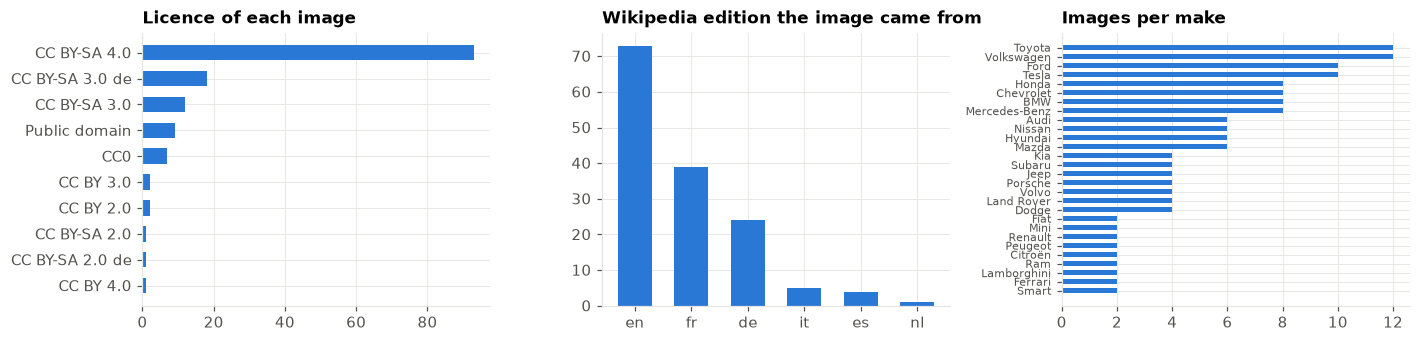

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
lic = images.license.str.replace(r"\s+", " ", regex=True).value_counts()
axes[0].barh(lic.index[::-1], lic.values[::-1], color=PALETTE[0], height=0.6)
axes[0].set_title("Licence of each image")
src = images.source_lang.value_counts()
axes[1].bar(src.index, src.values, color=PALETTE[0], width=0.6)
axes[1].set_title("Wikipedia edition the image came from")
per_make = images.make.value_counts()
axes[2].barh(per_make.index[::-1], per_make.values[::-1], color=PALETTE[0], height=0.6)
axes[2].set_title("Images per make")
axes[2].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

## 3. A first look at the images
A random sample. Note the spread: studio press shots, street photos, classic cars at shows, rear views.

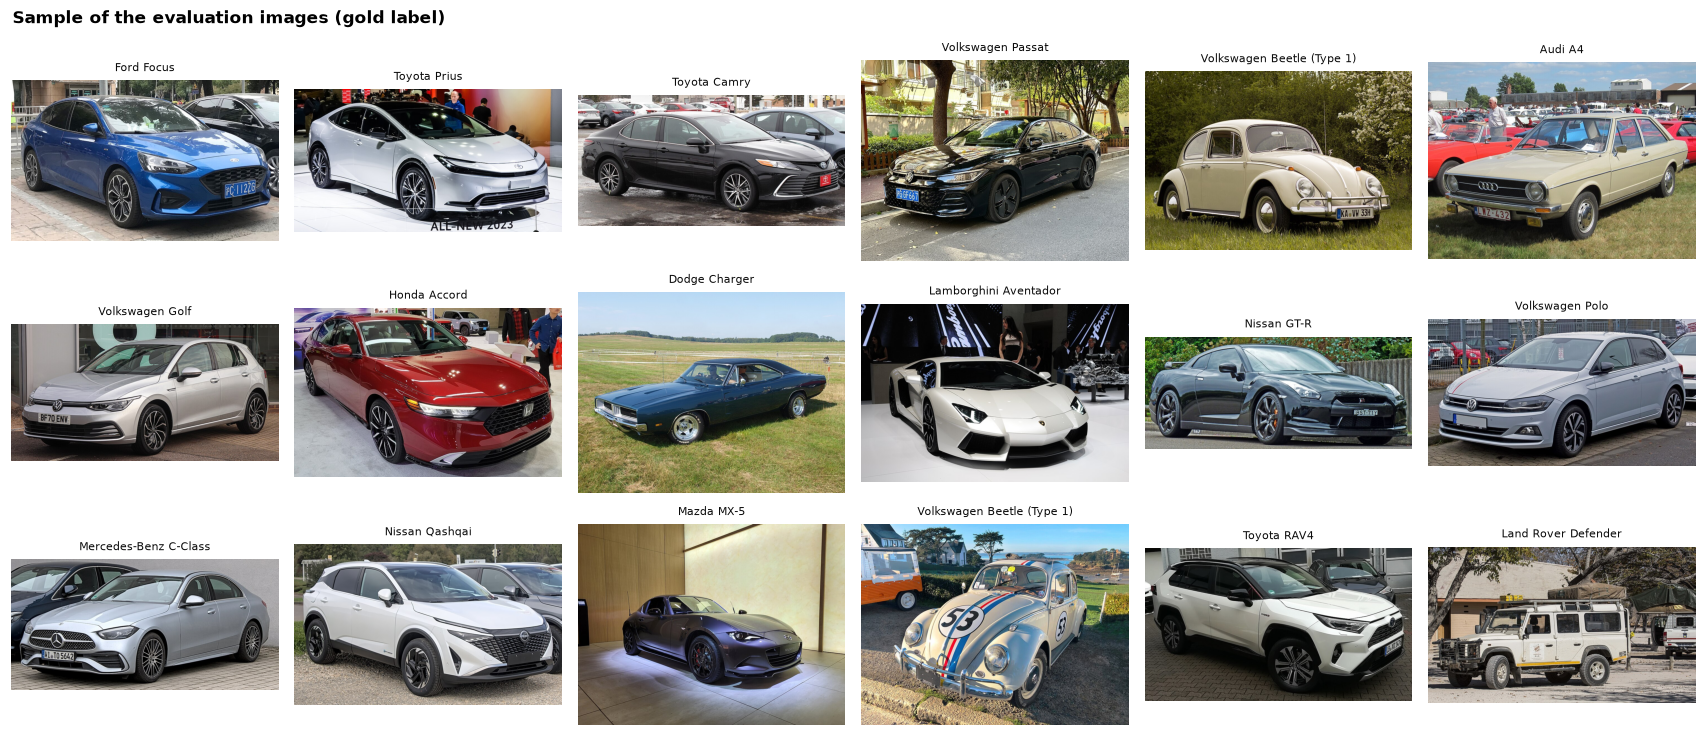

In [6]:
def show_grid(df, ncols=6, title=None, caption=None, path=None):
    n = len(df)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.3 * nrows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, row in zip(np.ravel(axes), df.itertuples()):
        ax.imshow(Image.open(row.path))
        text = caption(row) if caption else row.label
        color = INK
        if isinstance(text, tuple):
            text, color = text
        ax.set_title(text, fontsize=7.5, color=color, loc="center", fontweight="normal")
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=11)
    plt.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()


show_grid(images.sample(18, random_state=3), title="Sample of the evaluation images (gold label)")

## 4. Image annotation: view angle and visible badges
A photo with a readable "COROLLA" badge on the boot lid is an easier test than a badge-less side view. To
separate *recognising the car* from *reading the badge*, Claude Opus 5.5 annotates each image once:
the view angle and whether a make logo or model name is legible. These annotations are only used to slice
the results; they are not shown to any method.

In [7]:
ANNOTATE_PROMPT = """Look at this photo and answer in JSON only:
{"view": one of ["front", "front three-quarter", "side", "rear three-quarter", "rear", "other"],
 "make_logo_legible": true/false,      # a manufacturer logo or name is clearly readable
 "model_name_legible": true/false,     # the model name (e.g. a badge reading COROLLA or 320d) is clearly readable
 "single_car": true/false}             # one car is the clear subject of the photo
Do not identify the car."""


def annotate(path):
    out = ask_cli("claude", "claude-opus-5-5", ANNOTATE_PROMPT, images=[path], effort="low")
    return first_json(out.get("text"), key="view") or {}


ann = pd.DataFrame(pmap(annotate, images.path, WORKERS["claude"]))
images = pd.concat([images.drop(columns=[c for c in ann.columns if c in images], errors="ignore"), ann], axis=1)
pd.concat({c: images[c].astype(str).value_counts() for c in ["view", "make_logo_legible", "model_name_legible", "single_car"]}).rename("images").to_frame()

images
view               front three-quarter     135
                   other                     8
                   rear three-quarter        1
                   front                     1
                   side                      1
make_logo_legible  True                    108
                   False                    38
model_name_legible False                   111
                   True                     35
single_car         True                    137
                   False                     9

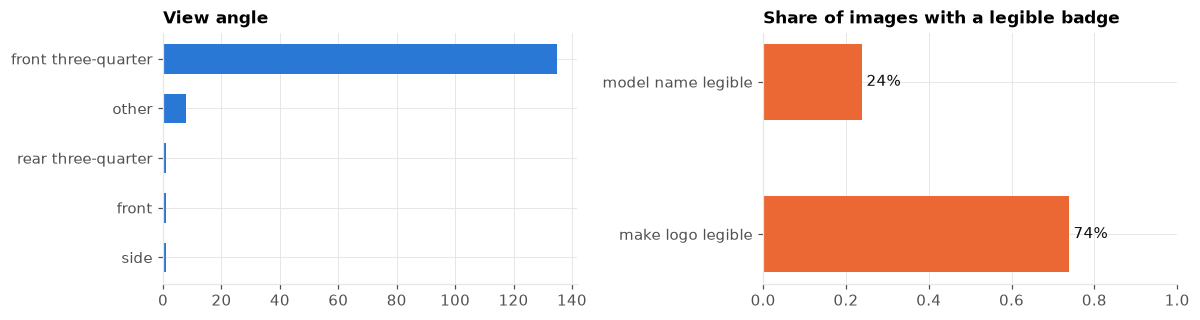

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
v = images.view.value_counts()
axes[0].barh(v.index[::-1], v.values[::-1], color=PALETTE[0], height=0.6)
axes[0].set_title("View angle")
badge = pd.Series({"make logo legible": images.make_logo_legible.eq(True).mean(),
                   "model name legible": images.model_name_legible.eq(True).mean()})
axes[1].barh(badge.index, badge.values, color=PALETTE[1], height=0.5)
axes[1].set_xlim(0, 1); axes[1].set_title("Share of images with a legible badge")
for i, val in enumerate(badge.values):
    axes[1].text(val + 0.01, i, f"{val:.0%}", va="center", color=INK)
plt.tight_layout(); plt.show()

## 5. Methods

Every method sees the same photo and the same 109 labels. The Decisions methods return a probability for every
label; the CLI models are asked for their top 3 labels with probabilities, so all six are scored the same way.
Decisions calls run 8 at a time; the CLI models run 4 (`claude`), 2 (`codex`) and 3 (`muse`) at a time.

```mermaid
flowchart LR
    img["One photo<br/>(146 in total)"]
    subgraph dec ["Decisions API: OpenRouter, image as the state"]
        a["A. Flat, detail high<br/>1 call: choice over 109 labels<br/>+ a body_type question<br/>returns P(label)"]
        cl["C. Flat, detail low<br/>the same call with a smaller image budget"]
        b1["B. Call 1<br/>choice over 28 makes<br/>returns P(make)"]
        b2["B. Call 2<br/>choice over the models of the top 2 makes<br/>score = P(make) × P(model given make)"]
        b1 -->|"top 2 makes"| b2
    end
    subgraph cli ["CLI vision models: effort medium, same prompt with the 109 labels"]
        d["D. Claude Opus 5.5<br/>claude -p, image as base64"]
        e["E. GPT-6.1<br/>codex exec -i, image file"]
        f["F. Muse Wonder<br/>muse exec, image file"]
    end
    o["Top 3 labels + confidence"]
    img --> a
    img --> cl
    img --> b1
    img --> d
    img --> e
    img --> f
    a --> o
    cl --> o
    b2 --> o
    d -->|"JSON: top 3 labels with p"| o
    e --> o
    f --> o
```

### 5.1 Decisions API
The API accepts at most 255 options per `choice` question, so all 109 labels fit in one question. Each label is
given as its name only. We add a `body_type` question in the same call: the image is billed once per call, so
extra questions are nearly free, and the body type helps explain errors.

* **A. flat**: one call, `choice` over 109 labels plus `body_type`.
* **B. hierarchical**: call 1 asks for the make (28 options). Call 2 asks for the model among the models of
  the two most likely makes. Final probability = P(make) × P(model | make).
* **C. flat, low detail**: as A, with `detail: "low"` on the image (a fixed small token budget).

In [9]:
LABEL_LIST = labels.label.tolist()
BODY_TYPES = ["sedan", "hatchback", "SUV / crossover", "pickup truck", "coupe / sports car", "convertible / roadster",
              "van / minibus", "station wagon"]
INSTR_MODEL = "Which car make and model is shown in the photo? Choose the single best match."
Q_FLAT = {
    "car": {"type": "choice", "instructions": INSTR_MODEL, "criteria": {l: l for l in LABEL_LIST}},
    "body_type": {"type": "choice", "instructions": "What body style is the car in the photo?",
                  "criteria": {b: b for b in BODY_TYPES}},
}


def top(probs, n=3):
    return sorted(probs, key=probs.get, reverse=True)[:n]


def method_flat(path, detail="high"):
    r = decide(path, Q_FLAT, detail=detail)
    if "error" in r or "refused" in r:
        return {"top": [], "conf": 0.0, "error": r.get("error") or "refused", "calls": []}
    p = r["answers"]["car"]["probabilities"]
    return {"top": top(p), "conf": max(p.values()), "body": r["answers"]["body_type"].get("choice"),
            "probs": p, "calls": [r]}


def method_hier(path, beam=2):
    r1 = decide(path, {"make": {"type": "choice", "instructions": "Which car manufacturer (make) built the car in the photo?",
                                "criteria": {m: m for m in MAKES}}})
    if "error" in r1 or "refused" in r1:
        return {"top": [], "conf": 0.0, "error": r1.get("error") or "refused", "calls": []}
    pm = r1["answers"]["make"]["probabilities"]
    keep = top(pm, beam)
    cand = labels.label[labels.make.isin(keep)].tolist()
    r2 = decide(path, {"car": {"type": "choice", "instructions": INSTR_MODEL, "criteria": {l: l for l in cand}}})
    if "error" in r2 or "refused" in r2:
        return {"top": [], "conf": 0.0, "error": r2.get("error") or "refused", "calls": [r1]}
    p2 = r2["answers"]["car"]["probabilities"]
    make_of = dict(zip(labels.label, labels.make))
    joint = {l: pm[make_of[l]] * p2[l] for l in cand}
    return {"top": top(joint), "conf": max(joint.values()), "calls": [r1, r2]}


preds = {}
preds["A. Decisions flat"] = pmap(method_flat, images.path, WORKERS["decisions"])
preds["B. Decisions make→model"] = pmap(method_hier, images.path, WORKERS["decisions"])
preds["C. Decisions flat, low detail"] = pmap(lambda p: method_flat(p, "low"), images.path, WORKERS["decisions"])
print({k: sum("error" in p for p in v) for k, v in preds.items()}, "errors")

{'A. Decisions flat': 1, 'B. Decisions make→model': 0, 'C. Decisions flat, low detail': 2} errors


### 5.2 Frontier vision models through their CLIs
Same image, same 109 labels. The prompt asks for the three most likely labels with probabilities that sum to
at most 1, so we can score top-1, top-3 and calibration the same way as for the Decisions API. Reasoning
effort is `medium` for all three.

In [10]:
CLI_PROMPT = """Identify the car in the photo. Pick from this list of make-model labels only:
{labels}

Reply with JSON only, no prose:
{{"top3": [{{"label": "<label from the list>", "p": <probability 0-1>}}, ...]}}
List the three most likely labels, most likely first. The probabilities must sum to at most 1."""


def method_cli(name, path):
    backend, model, effort = CLI_MODELS[name]
    out = ask_cli(backend, model, CLI_PROMPT.format(labels="\n".join(LABEL_LIST)), images=[path], effort=effort)
    if "error" in out:
        return {"top": [], "conf": 0.0, "error": out["error"], "latency_s": None}
    js = first_json(out["text"], key="top3") or {}
    items = [i for i in js.get("top3", []) if isinstance(i, dict) and i.get("label") in LABEL_LIST]
    if not items:
        return {"top": [], "conf": 0.0, "error": "unparseable: " + out["text"][:120], "latency_s": out["latency_s"]}
    return {"top": [i["label"] for i in items], "conf": float(items[0].get("p", 0) or 0),
            "latency_s": out["latency_s"], "list_cost_usd": out.get("list_cost_usd")}


if RUN_CLI_MODELS:
    for i, name in enumerate(CLI_MODELS):
        backend = CLI_MODELS[name][0]
        preds[f"{'DEF'[i]}. {name}"] = pmap(lambda p: method_cli(name, p), images.path, WORKERS[backend])
print({k: sum("error" in p for p in v) for k, v in preds.items()}, "errors")

{'A. Decisions flat': 1, 'B. Decisions make→model': 0, 'C. Decisions flat, low detail': 2, 'D. Claude Opus 5.5': 0, 'E. GPT-6.1 (Codex)': 0, 'F. Muse Wonder': 0} errors


## 6. Results
### 6.1 Accuracy, cost and latency
* **top-1 / top-3**: the gold label is the first / among the first three answers.
* **make acc**: the first answer has the right make (Toyota for a Corolla) even if the model is wrong.
* **$ / 1k images**: the Decisions API bills per token (`usage.cost`). The CLI rows show "n/a": those calls are
  billed to a subscription, not per request.
* **errors** counts replies with no usable answer: an unparseable reply, a failed call, or a Decisions API
  refusal (HTTP 502 "OpenAI refused to answer", which it returns for a few images). They count as wrong.

In [11]:
def bootstrap_ci(hits, n=2000, seed=0):
    hits = np.asarray(hits, dtype=float)
    rng = np.random.default_rng(seed)
    return np.percentile(rng.choice(hits, (n, len(hits))).mean(axis=1), [2.5, 97.5])


make_of = dict(zip(labels.label, labels.make))
rows, hits = [], {}
for name, P in preds.items():
    h1 = np.array([bool(p["top"]) and p["top"][0] == g for p, g in zip(P, images.label)])
    hits[name] = h1
    lo, hi = bootstrap_ci(h1)
    calls = [c for p in P for c in p.get("calls", [])]
    lat = [sum(c["latency_s"] for c in p["calls"]) for p in P if p.get("calls")] if calls else \
          [p["latency_s"] for p in P if p.get("latency_s")]
    rows.append({
        "method": name, "top-1": h1.mean(), "95% CI": f"[{lo:.2f}, {hi:.2f}]",
        "top-3": np.mean([g in p["top"][:3] for p, g in zip(P, images.label)]),
        "make acc": np.mean([bool(p["top"]) and make_of[p["top"][0]] == m for p, m in zip(P, images.make)]),
        "errors": sum("error" in p for p in P),
        "$ / 1k images": 1000 * sum(c["usage"]["cost"] for c in calls) / len(P) if calls else np.nan,
        "tokens / image": sum(c["usage"]["input_tokens"] for c in calls) / len(P) if calls else np.nan,
        "median latency s": float(np.median(lat)) if lat else np.nan,
    })
results = pd.DataFrame(rows).set_index("method")
results.to_csv(DATA / "results_summary.csv")
per_image = images[["image_id", "label", "view", "model_name_legible", "license", "page_url"]].copy()
for m, P in preds.items():
    per_image[m.split(". ")[1]] = [p["top"][0] if p["top"] else "" for p in P]
per_image.to_csv(DATA / "predictions.csv", index=False)
results.style.format({"top-1": "{:.1%}", "top-3": "{:.1%}", "make acc": "{:.1%}", "$ / 1k images": "${:.3f}",
                      "tokens / image": "{:,.0f}", "median latency s": "{:.1f}"}, na_rep="n/a") \
    .background_gradient(subset=["top-1", "top-3"], cmap="Blues", vmin=0, vmax=1)

,top-1,95% CI,top-3,make acc,errors,$ / 1k images,tokens / image,median latency s
method,,,,,,,,
A. Decisions flat,94.5%,"[0.90, 0.98]",98.6%,97.9%,1,$0.197,"1,966",0.9
B. Decisions make→model,93.8%,"[0.90, 0.98]",98.6%,98.6%,0,$0.160,"1,597",1.8
"C. Decisions flat, low detail",89.7%,"[0.85, 0.95]",96.6%,97.3%,2,$0.157,"1,570",0.9
D. Claude Opus 5.5,99.3%,"[0.98, 1.00]",100.0%,100.0%,0,n/a,n/a,5.6
E. GPT-6.1 (Codex),100.0%,"[1.00, 1.00]",100.0%,100.0%,0,n/a,n/a,4.4
F. Muse Wonder,100.0%,"[1.00, 1.00]",100.0%,100.0%,0,n/a,n/a,11.8


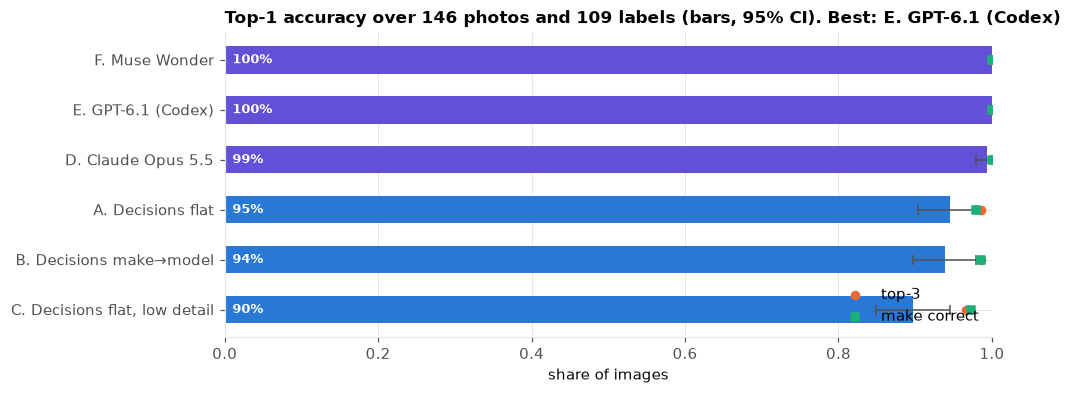

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
r = results.sort_values("top-1")
ci = np.array([bootstrap_ci(hits[m]) for m in r.index])
is_dec = r.index.str.contains("Decisions")
ax.barh(r.index, r["top-1"], color=[PALETTE[0] if d else PALETTE[6] for d in is_dec], height=0.55,
        xerr=[r["top-1"] - ci[:, 0], ci[:, 1] - r["top-1"]], error_kw={"ecolor": MUTED, "capsize": 3, "lw": 1})
ax.scatter(r["top-3"], r.index, color=PALETTE[1], zorder=3, s=28, label="top-3")
ax.scatter(r["make acc"], r.index, color=PALETTE[2], marker="s", zorder=3, s=24, label="make correct")
for y, v in enumerate(r["top-1"]):
    ax.text(0.01, y, f"{v:.0%}", va="center", color="white", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, 1); ax.set_xlabel("share of images")
best = r["top-1"].idxmax()
ax.set_title(f"Top-1 accuracy over {len(images)} photos and {len(labels)} labels (bars, 95% CI). Best: {best}")
ax.legend(loc="lower right")
fig.savefig(FIG / "accuracy_by_method.png"); plt.show()

### 6.2 Does a legible badge explain the accuracy?
If a method only reads badges, its accuracy should collapse on photos where no model name is legible.

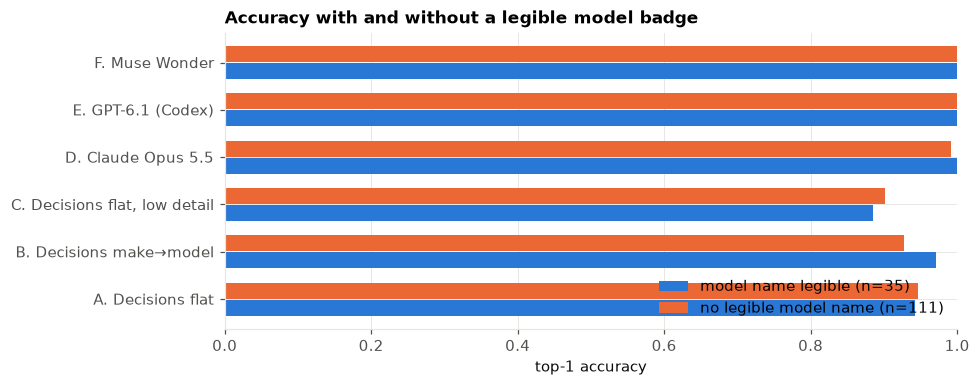

,model name legible,no legible model name
A. Decisions flat,94%,95%
B. Decisions make→model,97%,93%
"C. Decisions flat, low detail",89%,90%
D. Claude Opus 5.5,100%,99%
E. GPT-6.1 (Codex),100%,100%
F. Muse Wonder,100%,100%


In [13]:
images["badge"] = np.where(images.model_name_legible == True, "model name legible", "no legible model name")  # noqa: E712
by_badge = pd.DataFrame({m: pd.Series(hits[m]).groupby(images.badge.values).mean() for m in preds}).T
counts = images.badge.value_counts()
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(by_badge))
for j, (col, color) in enumerate(zip(by_badge.columns, [PALETTE[0], PALETTE[1]])):
    ax.barh(y + (j - 0.5) * 0.36, by_badge[col], height=0.34, color=color, label=f"{col} (n={counts.get(col, 0)})")
ax.set_yticks(y, by_badge.index); ax.set_xlim(0, 1); ax.set_xlabel("top-1 accuracy")
ax.set_title("Accuracy with and without a legible model badge"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
by_badge.style.format("{:.0%}")

### 6.3 Accuracy by view angle
Top-1 accuracy per view angle from the Claude annotation in section 4. 135 of the 146 photos are front
three-quarter views, so the other rows rest on 1 to 8 photos each.

In [14]:
by_view = pd.DataFrame({m.split(". ")[1]: pd.Series(hits[m]).groupby(images.view.values).mean() for m in preds})
by_view["n"] = images.view.value_counts()
by_view.sort_values("n", ascending=False).style.format("{:.0%}", subset=by_view.columns[:-1]) \
    .background_gradient(subset=by_view.columns[:-1], cmap="Blues", vmin=0, vmax=1)

,Decisions flat,Decisions make→model,"Decisions flat, low detail",Claude Opus 5.5,GPT-6.1 (Codex),Muse Wonder,n
front three-quarter,96%,95%,91%,99%,100%,100%,135
other,75%,88%,62%,100%,100%,100%,8
front,100%,0%,100%,100%,100%,100%,1
rear three-quarter,100%,100%,100%,100%,100%,100%,1
side,100%,100%,100%,100%,100%,100%,1


### 6.4 Are the Decisions API probabilities calibrated?
The Decisions API returns a probability for every label. If those numbers are calibrated, a system can
auto-accept confident answers and send the rest to a person. The left chart compares stated confidence with
observed accuracy (points above the diagonal mean the model is under-confident). The right chart shows the
accuracy you get if you only accept the most confident share of images. CLI models report a self-stated
probability, shown for comparison.

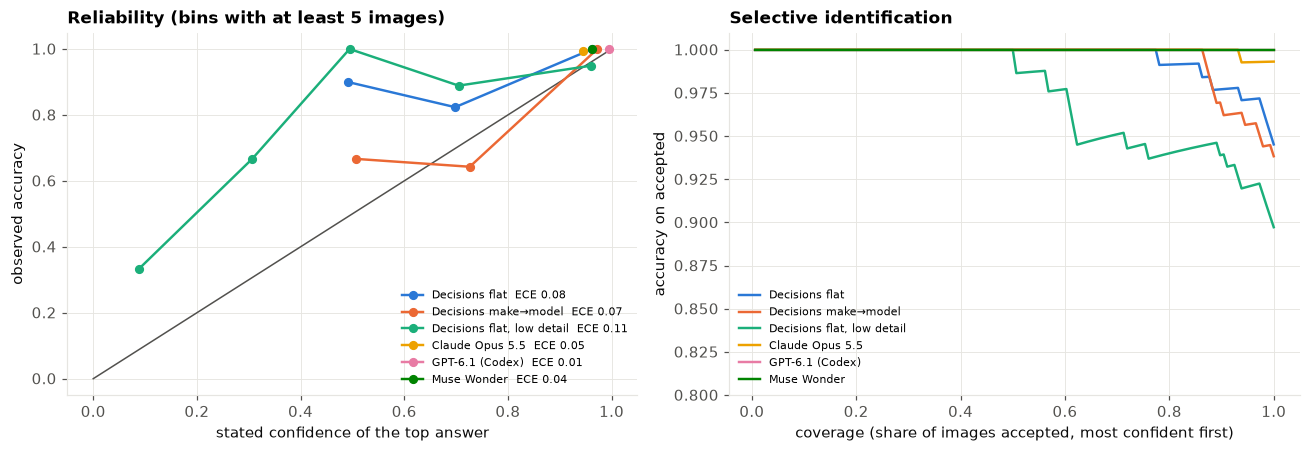

In [15]:
def ece(conf, hit, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    return sum(abs(conf[idx == b].mean() - hit[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any())


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot([0, 1], [0, 1], color=MUTED, lw=1)
for k, (m, P) in enumerate(preds.items()):
    conf = np.array([p["conf"] for p in P]); hit = hits[m]
    edges = np.linspace(0, 1, 6); idx = np.clip(np.digitize(conf, edges) - 1, 0, 4)
    pts = [(conf[idx == b].mean(), hit[idx == b].mean()) for b in range(5) if (idx == b).sum() >= 5]
    if pts:
        axes[0].plot(*zip(*pts), "o-", color=PALETTE[k], lw=1.6, ms=5, label=f"{m.split('. ')[1]}  ECE {ece(conf, hit):.2f}")
    order = np.argsort(-conf, kind="stable")
    cum = np.cumsum(hit[order]) / np.arange(1, len(hit) + 1)
    axes[1].plot(np.arange(1, len(hit) + 1) / len(hit), cum, color=PALETTE[k], lw=1.6, label=m.split(". ")[1])
axes[0].set_xlabel("stated confidence of the top answer"); axes[0].set_ylabel("observed accuracy")
axes[0].set_title("Reliability (bins with at least 5 images)"); axes[0].legend(fontsize=7)
axes[1].set_xlabel("coverage (share of images accepted, most confident first)"); axes[1].set_ylabel("accuracy on accepted")
axes[1].set_ylim(0.8, 1.01); axes[1].set_title("Selective identification"); axes[1].legend(fontsize=7)
plt.tight_layout(); fig.savefig(FIG / "calibration.png"); plt.show()

In [16]:
best_dec = results[results.index.str.contains("Decisions")]["top-1"].idxmax()
conf = np.array([p["conf"] for p in preds[best_dec]]); hit = hits[best_dec]
pd.DataFrame([{"accept if confidence ≥": t, "coverage": (conf >= t).mean(),
               "accuracy on accepted": hit[conf >= t].mean() if (conf >= t).any() else np.nan,
               "accuracy on the rest": hit[conf < t].mean() if (conf < t).any() else np.nan}
              for t in (0.0, 0.5, 0.7, 0.9, 0.97)]).style.format("{:.2f}").set_caption(f"Auto-accept thresholds for {best_dec}")

,accept if confidence ≥,coverage,accuracy on accepted,accuracy on the rest
0,0.00,1.00,0.95,nan
1,0.50,0.92,0.98,0.58
2,0.70,0.83,0.99,0.72
3,0.90,0.66,1.00,0.84
4,0.97,0.53,1.00,0.88


## 7. Error analysis
### 7.1 Every image, every method
Each row is a photo, each column a method. Green = correct top-1, light = gold label in top-3, red = wrong.
Rows are sorted by how many methods got the photo right, so the hard photos sit at the top.

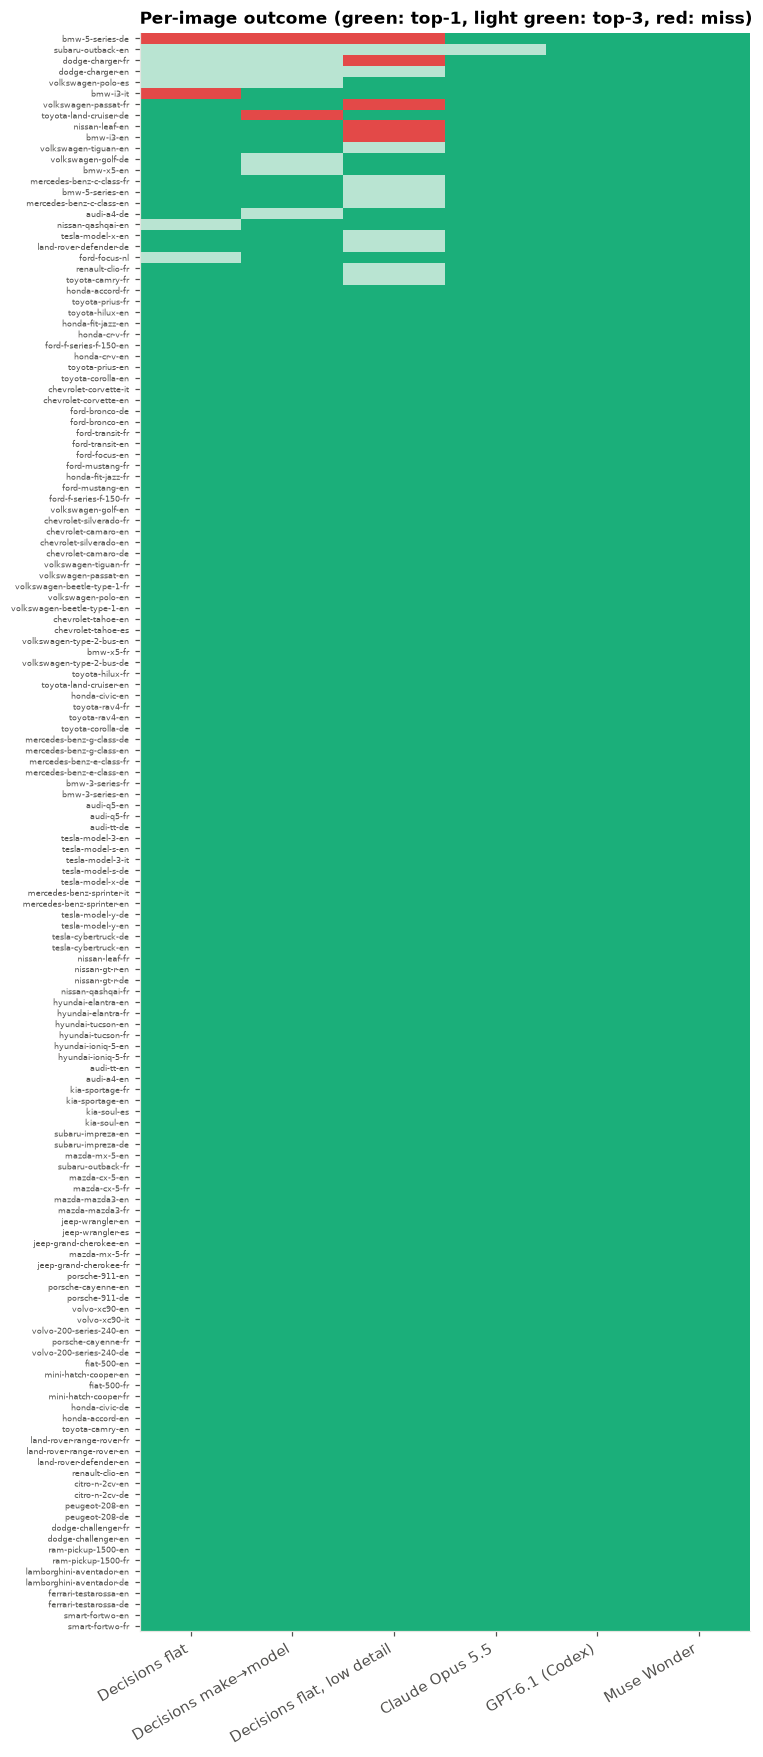

In [17]:
score = pd.DataFrame({m.split(". ")[1]: [2 if (p["top"] and p["top"][0] == g) else (1 if g in p["top"][:3] else 0)
                                         for p, g in zip(P, images.label)] for m, P in preds.items()},
                     index=images.image_id)
score = score.loc[score.sum(axis=1).sort_values().index]
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(7, max(4, len(score) * 0.11)))
ax.imshow(score.values, aspect="auto", cmap=ListedColormap([BAD, "#b9e4d2", GOOD]), vmin=0, vmax=2, interpolation="none")
ax.set_xticks(range(score.shape[1]), score.columns, rotation=30, ha="right")
ax.set_yticks(range(len(score)), score.index, fontsize=5.5); ax.grid(False)
ax.set_title("Per-image outcome (green: top-1, light green: top-3, red: miss)")
plt.tight_layout(); plt.show()

### 7.2 The photos the Decisions API got wrong
Caption: gold label, then the flat Decisions prediction with its probability.

8 of 146 wrong


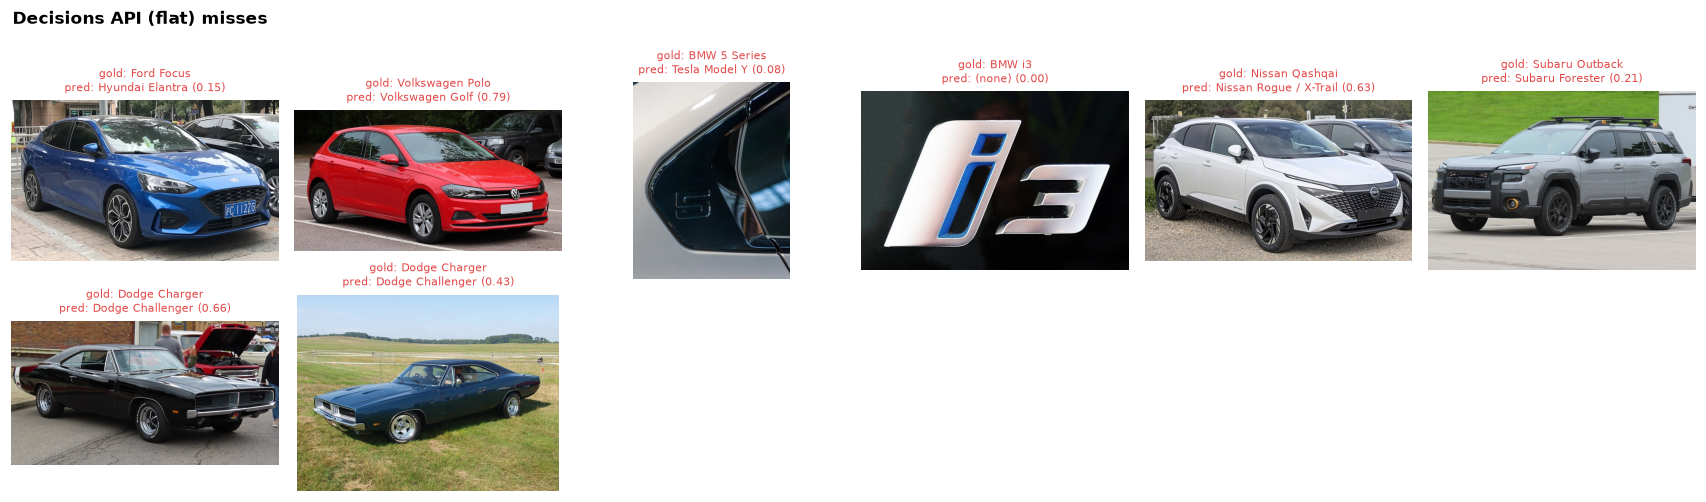

In [18]:
dec = preds["A. Decisions flat"]
wrong = images[[not (p["top"] and p["top"][0] == g) for p, g in zip(dec, images.label)]].copy()
wrong["pred"] = [dec[i]["top"][0] if dec[i]["top"] else "(none)" for i in wrong.index]
wrong["conf"] = [dec[i]["conf"] for i in wrong.index]
print(f"{len(wrong)} of {len(images)} wrong")
if len(wrong):
    show_grid(wrong.head(18), caption=lambda r: (f"gold: {r.label}\npred: {r.pred} ({r.conf:.2f})", BAD),
              title="Decisions API (flat) misses", path=FIG / "decisions_misses.png")

### 7.3 Most common confusions across all methods
Each row is a gold → predicted pair and the methods that made that error. 80% of all errors keep the right make,
as in the sibling-model misses shown in 7.2.

In [19]:
conf_rows = []
for m, P in preds.items():
    for p, g in zip(P, images.label):
        if p["top"] and p["top"][0] != g:
            conf_rows.append({"gold": g, "predicted": p["top"][0], "method": m.split(". ")[1],
                              "same make": make_of[p["top"][0]] == make_of[g]})
confusions = pd.DataFrame(conf_rows)
if len(confusions):
    tbl = confusions.groupby(["gold", "predicted", "same make"]).method.agg(["count", lambda s: ", ".join(sorted(set(s)))])
    tbl.columns = ["methods wrong", "which methods"]
    display(tbl.sort_values("methods wrong", ascending=False).head(15))
    print(f"Share of errors that keep the right make: {confusions['same make'].mean():.0%}")

methods wrong  \
gold                  predicted              same make                  
Dodge Charger         Dodge Challenger       True                   6   
Subaru Outback        Subaru Forester        True                   4   
Mercedes-Benz C-Class Mercedes-Benz E-Class  True                   2   
Volkswagen Polo       Volkswagen Golf        True                   2   
BMW 5 Series          Tesla Model Y          False                  1   
                      Porsche Macan          False                  1   
                      BMW 3 Series           True                   1   
Audi A4               Audi A3                True                   1   
Ford Focus            Hyundai Elantra        False                  1   
Land Rover Defender   Toyota Land Cruiser    False                  1   
BMW i3                BMW 3 Series           True                   1   
BMW X5                BMW X3                 True                   1   
Renault Clio          Renault Mégane         True                   1   
Nissan Qashqai        Nissan Rogue / X-Trail True                   1   
Toyota Camry          Toyota Corolla         True                   1   

                                                                                                                          which methods  
gold                  predicted              same make                                                                                   
Dodge Charger         Dodge Challenger       True                      Decisions flat, Decisions flat, low detail, Decisions make→model  
Subaru Outback        Subaru Forester        True       Claude Opus 5.5, Decisions flat, Decisions flat, low detail, Decisions make→...  
Mercedes-Benz C-Class Mercedes-Benz E-Class  True                                                            Decisions flat, low detail  
Volkswagen Polo       Volkswagen Golf        True                                                  Decisions flat, Decisions make→model  
BMW 5 Series          Tesla Model Y          False                                                                       Decisions flat  
                      Porsche Macan          False                                                                 Decisions make→model  
                      BMW 3 Series           True                                                            Decisions flat, low detail  
Audi A4               Audi A3                True                                                                  Decisions make→model  
Ford Focus            Hyundai Elantra        False                                                                       Decisions flat  
Land Rover Defender   Toyota Land Cruiser    False                                                           Decisions flat, low detail  
BMW i3                BMW 3 Series           True                                                            Decisions flat, low detail  
BMW X5                BMW X3                 True                                                                  Decisions make→model  
Renault Clio          Renault Mégane         True                                                            Decisions flat, low detail  
Nissan Qashqai        Nissan Rogue / X-Trail True                                                                        Decisions flat  
Toyota Camry          Toyota Corolla         True                                                            Decisions flat, low detail

Share of errors that keep the right make: 80%


## 8. Spend, limitations and how to reproduce
Spend recorded in the caches: Decisions API refusals, the Decisions cost, and the list-price equivalent of the
Claude CLI calls (billed to the subscription, not per call).

In [20]:
spent = sum(v["usage"]["cost"] for v in decisions_cache.data.values() if "usage" in v)
refusals = sum("refused" in v for v in decisions_cache.data.values())
print(f"Decisions API refusals (HTTP 502 'refused to answer'): {refusals}")
cli_list = sum(v.get("list_cost_usd") or 0 for v in cli_cache.data.values())
print(f"Decisions API spend recorded in the cache: ${spent:.4f} over {len(decisions_cache.data)} calls")
print(f"Claude CLI list-price equivalent (billed to the subscription): ${cli_list:.2f}")
print(f"CLI calls cached: {len(cli_cache.data)}")

Decisions API refusals (HTTP 502 'refused to answer'): 3
Decisions API spend recorded in the cache: $0.0749 over 584 calls
Claude CLI list-price equivalent (billed to the subscription): $5.64
CLI calls cached: 584


**Limitations**
* Wikipedia lead images are well-composed photos that the frontier models may have seen during training.
  Real-world photos (parking lots, dashcams, partial views) will be harder.
* 146 images: differences of a few points between methods are within the confidence intervals.
* The label set is closed (109 labels). Neither method is tested on cars outside the list.
* Gold labels come from the Wikipedia article the image illustrates. A lead image can show a close relative
  (for example a regional variant under another name). Section 7 lists every miss for inspection.

**Reproduce.** `pip install -r ../../requirements.txt`, then run all cells. With the caches in `data/` the run
makes no API calls. To rebuild from scratch, delete `data/cache_*.jsonl` (and `data/images*` to re-download
the photos); this needs `OPENROUTER_API_KEY` and logged-in `claude`, `codex` and `muse` CLIs.

## 9. Future work and further reading
Follow-up experiments that the results and limitations above point to, and sources for the methods and risks this notebook touches. Links checked on 17 October 2026.

### Future work
- Use harder photos. Wikipedia lead images are well-composed and may be in the models' training data. Test street, parking-lot and dashcam photos, and cars released after the models' training cut-off.
- Open the label set. Add photos of cars outside the 109 labels and measure whether the Decisions API's confidence drops enough to route them to review, since it always returns some label.
- Predict the generation or model year. Several misses are siblings or generations of the same model (a 1969 Charger read as a Challenger), and a year range is what a parts or insurance workflow needs.
- Add a non-LLM baseline. An open-weight image-text model such as CLIP, scoring the 109 label names, would show what a local model gets at near-zero cost against 94.5% top-1 for the Decisions API.

### Further reading
- [3D Object Representations for Fine-Grained Categorization](https://openaccess.thecvf.com/content_iccv_workshops_2013/W19/html/Krause_3D_Object_Representations_2013_ICCV_paper.html) (Krause et al., 2013). Introduced the Stanford Cars dataset, the usual fine-grained car benchmark. The original dataset page is offline.
- [A Large-Scale Car Dataset for Fine-Grained Categorization and Verification](https://arxiv.org/abs/1506.08959) (Yang et al., 2015). CompCars, with web and surveillance photos; the surveillance set is the harder kind of photo suggested above.
- [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020) (Radford et al., 2021). CLIP, the zero-shot image-text baseline suggested above.
- [Multimodal Decisions: Images, Audio, and Video in the Decisions API](https://openrouter.ai/docs/guides/community/multimodal-decisions) (OpenRouter guide). How images go into the Decisions API `state`, as `decide()` does here.
- [Commons:Reusing content outside Wikimedia](https://commons.wikimedia.org/wiki/Commons:Reusing_content_outside_Wikimedia) (Wikimedia Commons). The attribution and licence rules behind the author and licence columns in `data/images.csv`.